# Stroke Prediction — Midterm Project

**Machine Learning Zoomcamp 2026**

## Project overview

This project develops and evaluates binary classification models to estimate whether a record is associated with a stroke (`stroke = 1`) or no stroke (`stroke = 0`).

The notebook follows a reproducible machine-learning workflow:

1. Load and inspect the dataset.
2. Explore the target and predictor variables.
3. Split the data into training, validation, and test sets.
4. Fit preprocessing steps using the training set only.
5. Train and compare Logistic Regression, Decision Tree, Random Forest, and XGBoost.
6. Select a model and decision threshold using validation data.
7. Evaluate the selected configuration once on the held-out test set.
8. Save the model package for the prediction API.

> **Important:** This is an educational machine-learning project. It is not a medical device, diagnostic system, or substitute for professional medical advice. The dataset and model must not be used to make clinical decisions.

In [1]:
#!pip install pandas numpy matplotlib seaborn scikit-learn xgboost

## 1. Imports and configuration

We keep the random seed and feature definitions in one place so that experiments can be reproduced. The target is `stroke`; `id` is an identifier and is not used as a predictor.

In [2]:
import json                                               
import pickle                                             
import warnings                                           
from pathlib import Path                                  
                                                         
import matplotlib.pyplot as plt                           
import numpy as np                                        
import pandas as pd                                       
import seaborn as sns                                                                                              
                                                          
from sklearn.model_selection import train_test_split      
from sklearn.feature_extraction import DictVectorizer     
from sklearn.linear_model import LogisticRegression       
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier       
from sklearn.metrics import (                             
    roc_auc_score,                                        
    roc_curve,                                            
    confusion_matrix,                                     
    classification_report,                                
    accuracy_score,                                       
    precision_score,                                      
    recall_score,                                         
    f1_score,                                             
    ConfusionMatrixDisplay,                               
)                                                         
from sklearn.feature_selection import mutual_info_classif 
                                                          
                                                          
from xgboost import XGBClassifier                         

In [3]:
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
#df=pd.read_csv("healthcare-dataset-stroke-data_manipulated.csv")

DATA_PATH = Path("../healthcare-dataset-stroke-data_manipulated.csv")
MODEL_PATH = Path("stroke_prediction_model.bin")

TARGET = "stroke"
ID_COLUMN = "id"

NUMERICAL_FEATURES = [
    "age",
    "hypertension",
    "heart_disease",
    "avg_glucose_level",
    "bmi",
]

CATEGORICAL_FEATURES = [
    "gender",
    "ever_married",
    "work_type",
    "residence_type",
    "smoking_status",
]

FEATURES = CATEGORICAL_FEATURES + NUMERICAL_FEATURES

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

## 2. Load the dataset

Place `healthcare-dataset-stroke-data_manipulated.csv` in the same directory as this notebook. The source file is loaded without imputing or modifying values.

In [4]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}\n"
        "Place the CSV file beside this notebook or update DATA_PATH."
    )

df_raw = pd.read_csv(DATA_PATH)
print(f"Dataset shape: {df_raw.shape}")
display(df_raw.head())

Dataset shape: (4909, 12)


,id,gender,age,hypertension,heart disease,ever married,work type,Residence type,avg glucose level,bmi,smoking status,stroke
0,9046,Male,67.000,0,1,Yes,Private,Urban,228.690,36.600,formerly smoked,1
1,31112,Male,80.000,0,1,Yes,Private,Rural,105.920,32.500,never smoked,1
2,60182,Female,49.000,0,0,Yes,Private,Urban,171.230,34.400,smokes,1
3,1665,Female,79.000,1,0,Yes,Self-employed,Rural,174.120,24.000,never smoked,1
4,56669,Male,81.000,0,0,Yes,Private,Urban,186.210,29.000,formerly smoked,1


## 3. Initial data quality checks

Normalize column names and categorical text consistently. These transformations do not learn statistics from the data and can safely happen before splitting. We retain the original dataframe separately for traceability.

In [5]:
df = df_raw.copy()

# Normalize column names: lowercase and replace groups of spaces with underscores.
df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"\s+", "_", regex=True)
)

# Normalize categorical text without converting missing values into the string "nan".
raw_categorical = df.select_dtypes(include=["object", "string"]).columns.tolist()
for column in raw_categorical:
    df[column] = (
        df[column]
        .astype("string")
        .str.strip()
        .str.lower()
        .str.replace(r"\s+", "_", regex=True)
    )

# Check that the expected fields exist.
required_columns = [ID_COLUMN, TARGET] + FEATURES
missing_columns = sorted(set(required_columns) - set(df.columns))
if missing_columns:
    raise ValueError(f"Required columns are missing: {missing_columns}")

display(df.dtypes.to_frame("dtype"))

,dtype
id,int64
gender,string
age,float64
hypertension,int64
heart_disease,int64
ever_married,string
work_type,string
residence_type,string
avg_glucose_level,float64
bmi,float64


In [6]:
print("Missing values per column:")
display(df.isna().sum().to_frame("missing_count"))

print(f"Duplicate rows: {df.duplicated().sum()}")
print("\nTarget counts:")
display(df[TARGET].value_counts().sort_index().to_frame("count"))

print("\nTarget proportions:")
display(df[TARGET].value_counts(normalize=True).sort_index().to_frame("proportion"))

Missing values per column:


,missing_count
id,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
residence_type,0
avg_glucose_level,0
bmi,0


Duplicate rows: 0

Target counts:


,count
stroke,
0,3862
1,1047



Target proportions:


,proportion
stroke,
0,0.787
1,0.213


## 4. Exploratory data analysis (EDA)

EDA is descriptive. Any learned preprocessing values (such as medians or modes) will be calculated later from the training split only.

In [7]:
display(df[FEATURES + [TARGET]].describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
gender,4909,3,female,2897,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ever_married,4909,2,yes,3204,NaN,NaN,NaN,NaN,NaN,NaN,NaN
work_type,4909,5,private,2811,NaN,NaN,NaN,NaN,NaN,NaN,NaN
residence_type,4909,2,urban,2490,NaN,NaN,NaN,NaN,NaN,NaN,NaN
smoking_status,4909,4,never_smoked,1852,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,"4,909.000",NaN,NaN,NaN,42.865,22.555,0.080,25.000,44.000,60.000,82.000
hypertension,"4,909.000",NaN,NaN,NaN,0.092,0.289,0.000,0.000,0.000,0.000,1.000
heart_disease,"4,909.000",NaN,NaN,NaN,0.050,0.217,0.000,0.000,0.000,0.000,1.000
avg_glucose_level,"4,909.000",NaN,NaN,NaN,105.305,44.424,55.120,77.070,91.680,113.570,271.740
bmi,"4,909.000",NaN,NaN,NaN,28.893,7.854,10.300,23.500,28.100,33.100,97.600


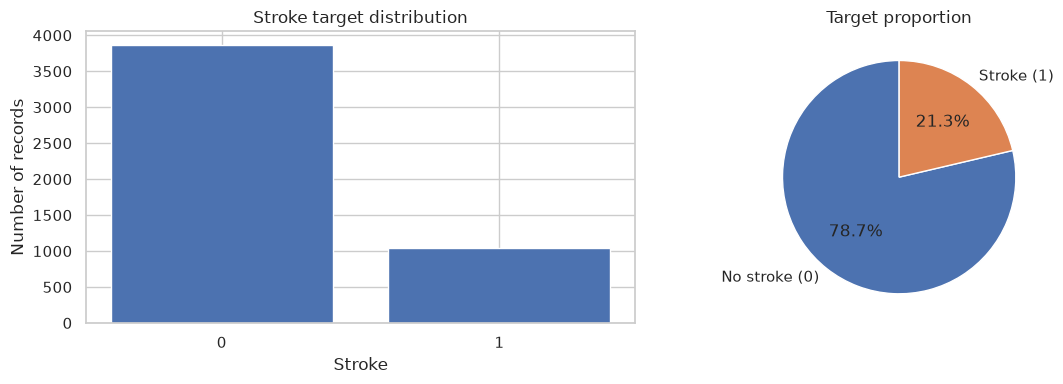

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

target_counts = df[TARGET].value_counts().sort_index()
axes[0].bar(target_counts.index.astype(str), target_counts.values)
axes[0].set_title("Stroke target distribution")
axes[0].set_xlabel("Stroke")
axes[0].set_ylabel("Number of records")

target_share = df[TARGET].value_counts(normalize=True).sort_index()
axes[1].pie(
    target_share.values,
    labels=[f"No stroke (0)", f"Stroke (1)"],
    autopct="%1.1f%%",
    startangle=90,
)
axes[1].set_title("Target proportion")

plt.tight_layout()
plt.show()

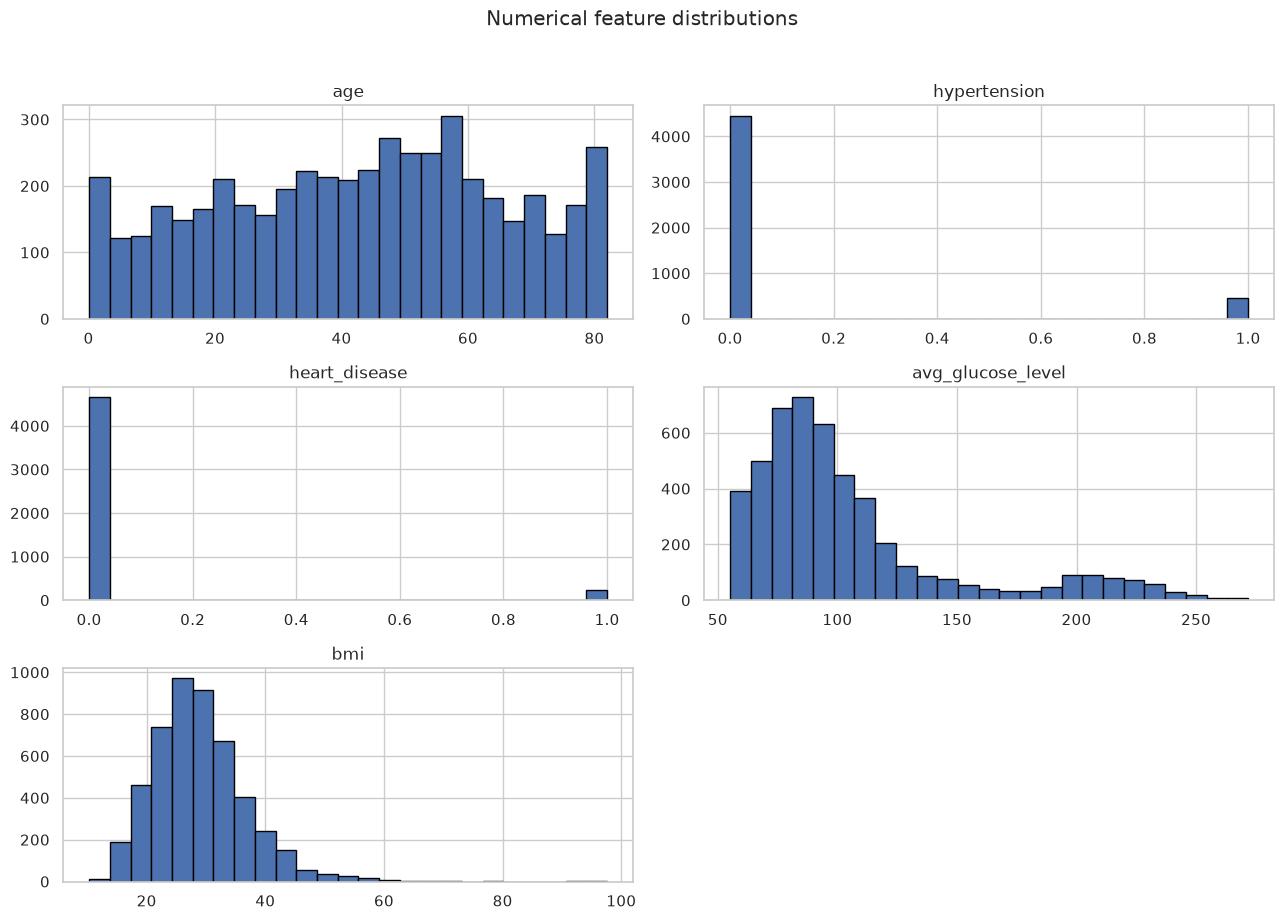

In [9]:
numeric_for_eda = df[NUMERICAL_FEATURES].copy()
numeric_for_eda.hist(figsize=(13, 9), bins=25, edgecolor="black")
plt.suptitle("Numerical feature distributions", y=1.02)
plt.tight_layout()
plt.show()

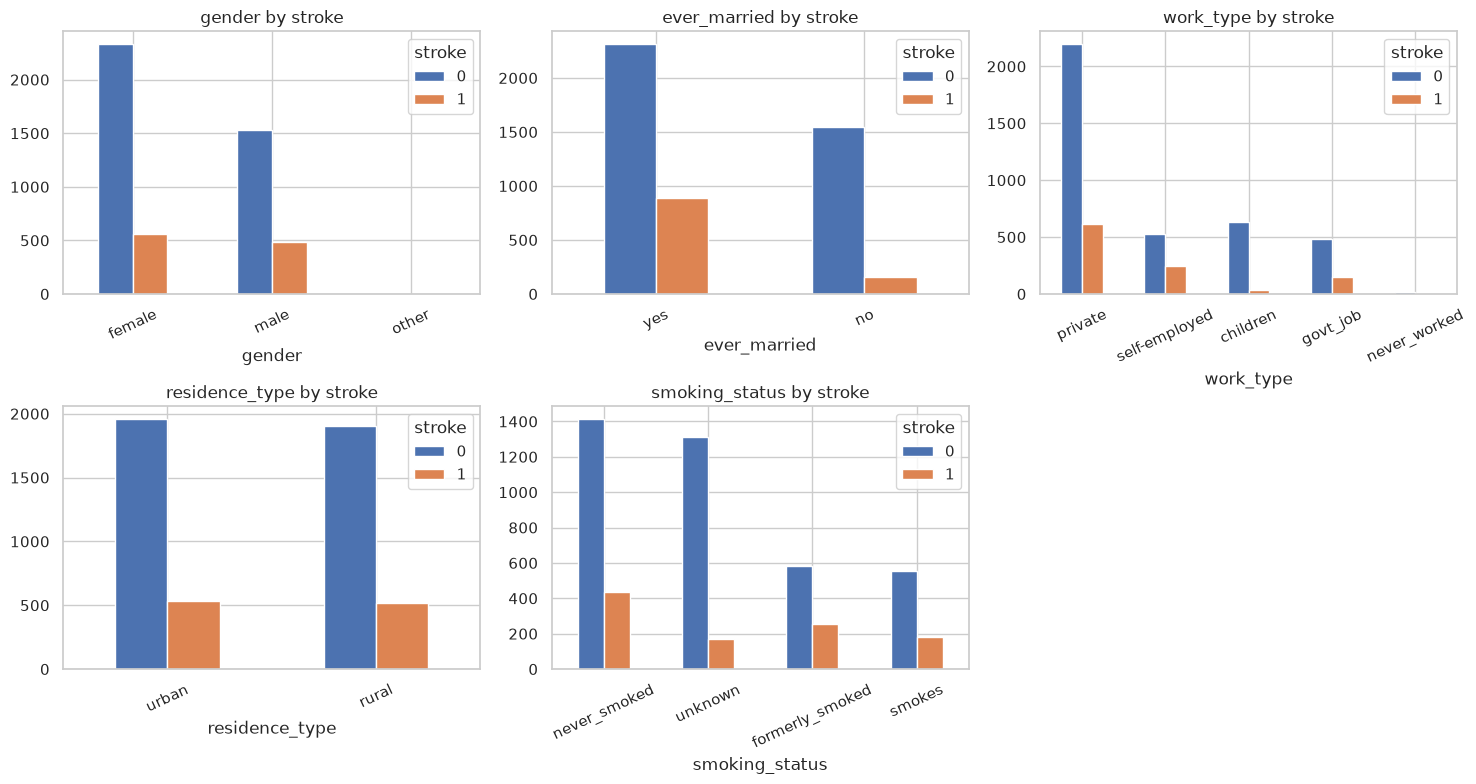

In [10]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for column, ax in zip(CATEGORICAL_FEATURES, axes.flat):
    order = df[column].value_counts().index
    pd.crosstab(df[column], df[TARGET]).reindex(order).plot(kind="bar", ax=ax)
    ax.set_title(f"{column} by stroke")
    ax.tick_params(axis="x", rotation=25)
    ax.legend(title=TARGET)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

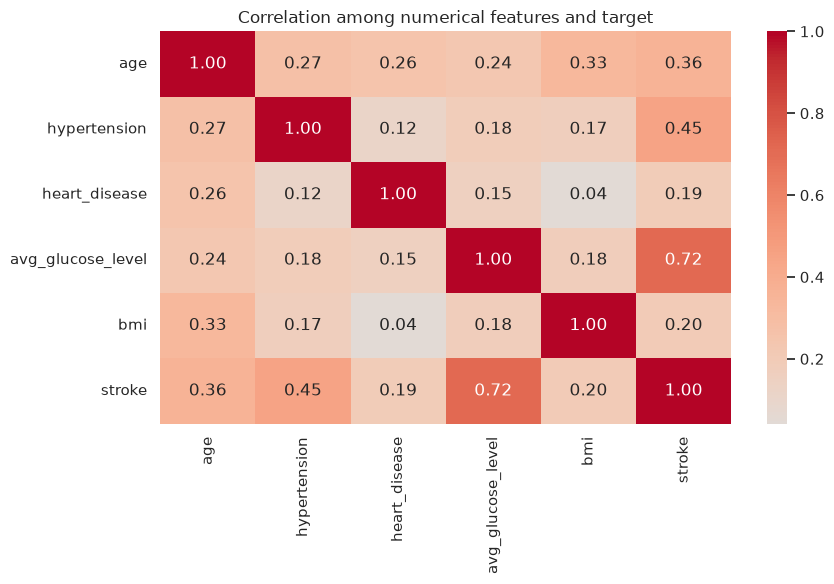

In [11]:
correlation_data = df[NUMERICAL_FEATURES + [TARGET]].corr(numeric_only=True)

plt.figure(figsize=(9, 6))
sns.heatmap(correlation_data, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation among numerical features and target")
plt.tight_layout()
plt.show()

## 5. Train / validation / test split

We use a 60% / 20% / 20% split. Stratification preserves approximately the same target-class proportion in each partition. The test set is held aside and is not used for model selection or threshold tuning.

In [12]:
df_train_full, df_test = train_test_split(
    df,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df[TARGET],
)

df_train, df_val = train_test_split(
    df_train_full,
    test_size=0.25,
    random_state=RANDOM_STATE,
    stratify=df_train_full[TARGET],
)

# Reset indexes for clean, aligned dataframes.
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

def show_split(name, frame):
    print(
        f"{name:12s}: {len(frame):4d} rows "
        f"({len(frame) / len(df):.1%}) | "
        f"stroke rate = {frame[TARGET].mean():.3f}"
    )

show_split("Training", df_train)
show_split("Validation", df_val)
show_split("Test", df_test)

Training    : 2945 rows (60.0%) | stroke rate = 0.213
Validation  :  982 rows (20.0%) | stroke rate = 0.214
Test        :  982 rows (20.0%) | stroke rate = 0.213


## 6. Fit preprocessing on training data only

The original notebook imputed missing values before splitting. That can leak information from validation and test into training. Here, medians and modes are learned only from `df_train`, then applied unchanged to all three partitions.

The BMI upper cap of 60 is retained as a fixed, explicitly chosen data-cleaning rule from the original project. It is not estimated from validation or test data. We report how many values it affects.

In [13]:
# Learn imputation values from the training partition only.
numerical_medians = df_train[NUMERICAL_FEATURES].median()
categorical_modes = df_train[CATEGORICAL_FEATURES].mode(dropna=True).iloc[0]

print("Training medians:")
display(numerical_medians.to_frame("median"))

print("Training modes:")
display(categorical_modes.to_frame("mode"))

Training medians:


,median
age,44.000
hypertension,0.000
heart_disease,0.000
avg_glucose_level,91.630
bmi,28.100


Training modes:


,mode
gender,female
ever_married,yes
work_type,private
residence_type,urban
smoking_status,never_smoked


In [14]:
def preprocess_features(frame):
    result = frame[FEATURES].copy()

    for column in NUMERICAL_FEATURES:
        result[column] = result[column].fillna(numerical_medians[column])

    for column in CATEGORICAL_FEATURES:
        result[column] = result[column].fillna(categorical_modes[column])
        result[column] = result[column].astype(str)

    # Fixed domain rule retained from the original analysis.
    result["bmi"] = result["bmi"].clip(upper=60)

    return result

X_train_df = preprocess_features(df_train)
X_val_df = preprocess_features(df_val)
X_test_df = preprocess_features(df_test)

y_train = df_train[TARGET].astype(int).to_numpy()
y_val = df_val[TARGET].astype(int).to_numpy()
y_test = df_test[TARGET].astype(int).to_numpy()

print("Missing values after preprocessing:")
print("Train:", X_train_df.isna().sum().sum())
print("Validation:", X_val_df.isna().sum().sum())
print("Test:", X_test_df.isna().sum().sum())

print("\nFeature matrix source shapes:")
print("Train:", X_train_df.shape)
print("Validation:", X_val_df.shape)
print("Test:", X_test_df.shape)

Missing values after preprocessing:
Train: 0
Validation: 0
Test: 0

Feature matrix source shapes:
Train: (2945, 10)
Validation: (982, 10)
Test: (982, 10)


## 7. Encode features with DictVectorizer

`DictVectorizer` is fitted only on training records. Validation and test records are transformed using the already-fitted vectorizer. This also keeps the model artifact compatible with the existing Flask API design, which transforms incoming dictionaries with `dv.transform()`.

In [15]:
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(X_train_df.to_dict(orient="records"))
X_val = dv.transform(X_val_df.to_dict(orient="records"))
X_test = dv.transform(X_test_df.to_dict(orient="records"))

feature_names = dv.get_feature_names_out()

print("X_train:", X_train.shape)
print("X_val:  ", X_val.shape)
print("X_test: ", X_test.shape)
print("Encoded features:", len(feature_names))

X_train: (2945, 21)
X_val:   (982, 21)
X_test:  (982, 21)
Encoded features: 21


## 8. Baseline model — Logistic Regression

Logistic Regression provides a useful baseline. ROC AUC is calculated from predicted probabilities rather than hard class predictions.

In [16]:
baseline_lr = LogisticRegression(
    solver="liblinear",
    C=1.0,
    max_iter=1000,
    random_state=RANDOM_STATE,
)
baseline_lr.fit(X_train, y_train)

lr_val_prob = baseline_lr.predict_proba(X_val)[:, 1]
lr_val_auc = roc_auc_score(y_val, lr_val_prob)

print(f"Logistic Regression validation ROC AUC: {lr_val_auc:.4f}")

Logistic Regression validation ROC AUC: 0.9715


In [17]:
lr_tuning_results = []

for c_value in [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 0.1, 1, 10, 100]:
    candidate = LogisticRegression(
        solver="liblinear",
        C=c_value,
        max_iter=1000,
        random_state=RANDOM_STATE,
    )
    candidate.fit(X_train, y_train)
    probabilities = candidate.predict_proba(X_val)[:, 1]
    lr_tuning_results.append({
        "C": c_value,
        "validation_auc": roc_auc_score(y_val, probabilities),
    })

lr_tuning_df = pd.DataFrame(lr_tuning_results).sort_values(
    "validation_auc", ascending=False
)
display(lr_tuning_df)

,C,validation_auc
7,10.000,0.972
8,100.000,0.972
6,1.000,0.971
5,0.100,0.964
4,0.010,0.884
3,0.001,0.778
2,0.000,0.747
1,0.000,0.651
0,0.000,0.111


## 9. Decision Tree — hyperparameter tuning

We search a small, transparent grid of tree depths and minimum leaf sizes. The best configuration is selected using validation ROC AUC only.

In [18]:
dt_results = []

for depth in [3, 5, 7, 10, None]:
    for leaf in [1, 5, 10, 20, 50]:
        candidate = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=leaf,
            random_state=RANDOM_STATE,
        )
        candidate.fit(X_train, y_train)
        probabilities = candidate.predict_proba(X_val)[:, 1]
        dt_results.append({
            "max_depth": depth,
            "min_samples_leaf": leaf,
            "validation_auc": roc_auc_score(y_val, probabilities),
        })

dt_results_df = pd.DataFrame(dt_results).sort_values(
    "validation_auc", ascending=False
).reset_index(drop=True)

display(dt_results_df.head(10))

,max_depth,min_samples_leaf,validation_auc
0,5.000,1,0.978
1,5.000,20,0.978
2,5.000,50,0.978
3,5.000,5,0.974
4,5.000,10,0.974
5,7.000,20,0.970
6,NaN,50,0.969
7,10.000,50,0.969
8,7.000,50,0.969
9,7.000,1,0.966


In [19]:
best_dt_params = dt_results_df.iloc[0]
best_dt = DecisionTreeClassifier(
    max_depth=None if pd.isna(best_dt_params["max_depth"]) else int(best_dt_params["max_depth"]),
    min_samples_leaf=int(best_dt_params["min_samples_leaf"]),
    random_state=RANDOM_STATE,
)
best_dt.fit(X_train, y_train)

dt_val_prob = best_dt.predict_proba(X_val)[:, 1]
dt_val_auc = roc_auc_score(y_val, dt_val_prob)

print("Best Decision Tree parameters:")
print(best_dt.get_params())
print(f"Decision Tree validation ROC AUC: {dt_val_auc:.4f}")

Best Decision Tree parameters:
{'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 5, 'max_features': None, 'max_leaf_nodes': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 1, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'random_state': 42, 'splitter': 'best'}
Decision Tree validation ROC AUC: 0.9779


## 10. Random Forest — hyperparameter tuning

Random Forest averages predictions from multiple decision trees. We compare a compact set of tree counts, depths, and minimum leaf sizes.

In [20]:
rf_results = []

for n_estimators in [100, 200, 300]:
    for depth in [5, 7, 10, None]:
        for leaf in [5, 10, 20]:
            candidate = RandomForestClassifier(
                n_estimators=n_estimators,
                max_depth=depth,
                min_samples_leaf=leaf,
                random_state=RANDOM_STATE,
                n_jobs=-1,
            )
            candidate.fit(X_train, y_train)
            probabilities = candidate.predict_proba(X_val)[:, 1]
            rf_results.append({
                "n_estimators": n_estimators,
                "max_depth": depth,
                "min_samples_leaf": leaf,
                "validation_auc": roc_auc_score(y_val, probabilities),
            })

rf_results_df = pd.DataFrame(rf_results).sort_values(
    "validation_auc", ascending=False
).reset_index(drop=True)

display(rf_results_df.head(10))

,n_estimators,max_depth,min_samples_leaf,validation_auc
0,300,5.000,5,0.983
1,300,5.000,10,0.983
2,200,5.000,5,0.983
3,200,5.000,10,0.983
4,100,5.000,10,0.983
5,100,5.000,5,0.983
6,300,5.000,20,0.983
7,100,5.000,20,0.983
8,200,5.000,20,0.982
9,200,10.000,10,0.982


In [21]:
rf_best = rf_results_df.iloc[0]
best_rf = RandomForestClassifier(
    n_estimators=int(rf_best["n_estimators"]),
    max_depth=None if pd.isna(rf_best["max_depth"]) else int(rf_best["max_depth"]),
    min_samples_leaf=int(rf_best["min_samples_leaf"]),
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
best_rf.fit(X_train, y_train)

rf_val_prob = best_rf.predict_proba(X_val)[:, 1]
rf_val_auc = roc_auc_score(y_val, rf_val_prob)

print("Best Random Forest parameters:")
print(best_rf.get_params())
print(f"Random Forest validation ROC AUC: {rf_val_auc:.4f}")

Best Random Forest parameters:
{'bootstrap': True, 'ccp_alpha': 0.0, 'class_weight': None, 'criterion': 'gini', 'max_depth': 5, 'max_features': 'sqrt', 'max_leaf_nodes': None, 'max_samples': None, 'min_impurity_decrease': 0.0, 'min_samples_leaf': 5, 'min_samples_split': 2, 'min_weight_fraction_leaf': 0.0, 'monotonic_cst': None, 'n_estimators': 300, 'n_jobs': -1, 'oob_score': False, 'random_state': 42, 'verbose': 0, 'warm_start': False}
Random Forest validation ROC AUC: 0.9831


## 11. XGBoost — hyperparameter tuning

XGBoost is a gradient-boosted tree model. The experiment below uses a modest grid to keep runtime manageable. If XGBoost is unavailable, install the project requirements before running this section.

In [22]:
xgb_results = []

for n_estimators in [100, 200, 300]:
    for depth in [2, 3, 4, 5]:
        for learning_rate in [0.01, 0.05, 0.1]:
            candidate = XGBClassifier(
                n_estimators=n_estimators,
                max_depth=depth,
                learning_rate=learning_rate,
                objective="binary:logistic",
                eval_metric="logloss",
                subsample=1.0,
                colsample_bytree=1.0,
                random_state=RANDOM_STATE,
                n_jobs=-1,
            )
            candidate.fit(X_train, y_train)
            probabilities = candidate.predict_proba(X_val)[:, 1]
            xgb_results.append({
                "n_estimators": n_estimators,
                "max_depth": depth,
                "learning_rate": learning_rate,
                "validation_auc": roc_auc_score(y_val, probabilities),
            })

xgb_results_df = pd.DataFrame(xgb_results).sort_values(
    "validation_auc", ascending=False
).reset_index(drop=True)

display(xgb_results_df.head(10))

,n_estimators,max_depth,learning_rate,validation_auc
0,100,2,0.050,0.984
1,200,3,0.010,0.984
2,300,3,0.010,0.983
3,300,2,0.010,0.983
4,100,3,0.050,0.983
5,100,4,0.010,0.982
6,100,2,0.100,0.982
7,200,2,0.050,0.982
8,100,3,0.100,0.981
9,200,3,0.050,0.981


In [23]:
xgb_best = xgb_results_df.iloc[0]
best_xgb = XGBClassifier(
    n_estimators=int(xgb_best["n_estimators"]),
    max_depth=int(xgb_best["max_depth"]),
    learning_rate=float(xgb_best["learning_rate"]),
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
best_xgb.fit(X_train, y_train)

xgb_val_prob = best_xgb.predict_proba(X_val)[:, 1]
xgb_val_auc = roc_auc_score(y_val, xgb_val_prob)

print("Best XGBoost parameters:")
print(best_xgb.get_params())
print(f"XGBoost validation ROC AUC: {xgb_val_auc:.4f}")

Best XGBoost parameters:
{'objective': 'binary:logistic', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': None, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': True, 'eval_metric': 'logloss', 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.05, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 2, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 100, 'n_jobs': -1, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': None, 'tree_method': None, 'validate_parameters': None, 'verbosity': None}
XGBoost validation ROC AUC: 0.9837


## 12. Compare candidate models on validation data

All models are compared on the same validation partition. The test set remains untouched.

In [24]:
models = {
    "Logistic Regression": baseline_lr,
    "Decision Tree": best_dt,
    "Random Forest": best_rf,
    "XGBoost": best_xgb,
}

validation_probabilities = {
    name: model.predict_proba(X_val)[:, 1]
    for name, model in models.items()
}

comparison = pd.DataFrame([
    {
        "model": name,
        "validation_roc_auc": roc_auc_score(y_val, probabilities),
    }
    for name, probabilities in validation_probabilities.items()
]).sort_values("validation_roc_auc", ascending=False).reset_index(drop=True)

display(comparison)

,model,validation_roc_auc
0,XGBoost,0.984
1,Random Forest,0.983
2,Decision Tree,0.978
3,Logistic Regression,0.971


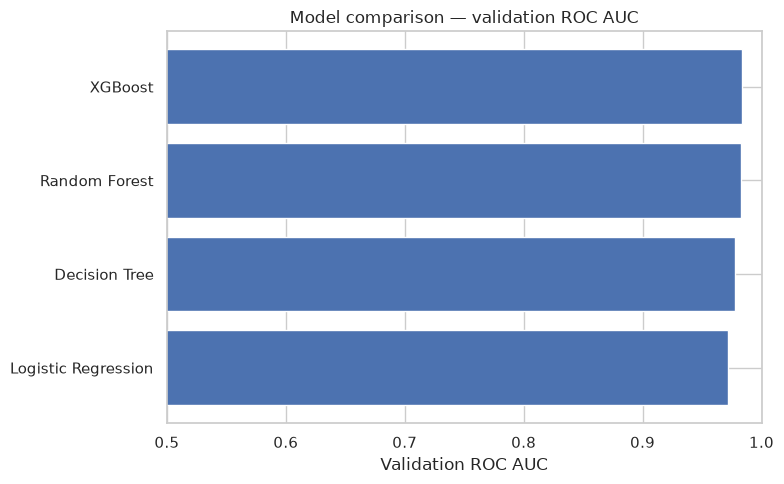

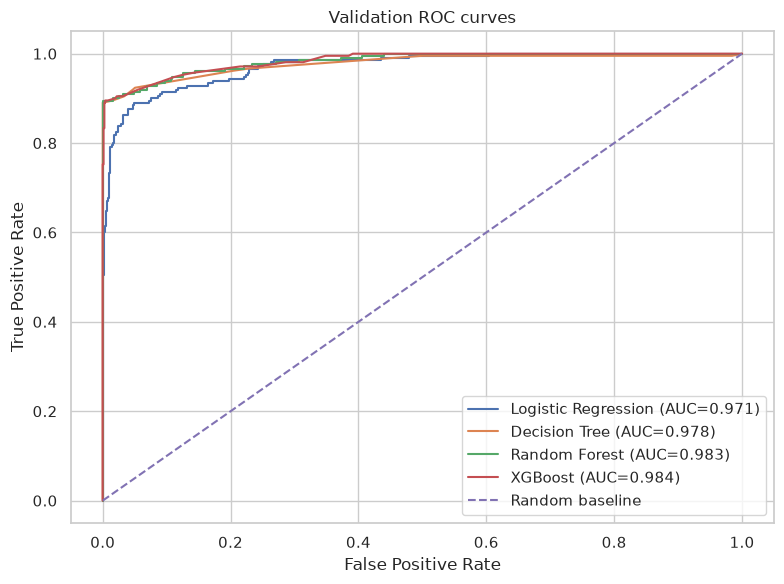

In [25]:
plt.figure(figsize=(8, 5))
plt.barh(comparison["model"], comparison["validation_roc_auc"])
plt.gca().invert_yaxis()
plt.xlim(0.5, 1.0)
plt.title("Model comparison — validation ROC AUC")
plt.xlabel("Validation ROC AUC")
plt.ylabel("")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
for name, probabilities in validation_probabilities.items():
    fpr, tpr, _ = roc_curve(y_val, probabilities)
    auc_value = roc_auc_score(y_val, probabilities)
    plt.plot(fpr, tpr, label=f"{name} (AUC={auc_value:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Validation ROC curves")
plt.legend()
plt.tight_layout()
plt.show()

## 13. Select the model and tune the decision threshold

The model with the highest validation ROC AUC is selected automatically. We then choose a threshold by maximizing validation F1 score. This is a project selection rule, not a clinically optimized threshold; in a real medical setting, the trade-off between false negatives and false positives requires clinical input.

In [26]:
selected_model_name = comparison.iloc[0]["model"]
selected_model = models[selected_model_name]
selected_val_prob = validation_probabilities[selected_model_name]

threshold_rows = []
for threshold in np.arange(0.10, 0.91, 0.05):
    predictions = (selected_val_prob >= threshold).astype(int)
    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "precision": precision_score(y_val, predictions, zero_division=0),
        "recall": recall_score(y_val, predictions, zero_division=0),
        "f1": f1_score(y_val, predictions, zero_division=0),
    })

threshold_results = pd.DataFrame(threshold_rows)
threshold_results = threshold_results.sort_values(
    ["f1", "threshold"], ascending=[False, True]
).reset_index(drop=True)

display(threshold_results)

,threshold,precision,recall,f1
0,0.450,0.984,0.895,0.938
1,0.550,0.989,0.890,0.937
2,0.500,0.984,0.890,0.935
3,0.400,0.974,0.895,0.933
4,0.200,0.969,0.895,0.931
5,0.250,0.969,0.895,0.931
6,0.300,0.969,0.895,0.931
7,0.350,0.969,0.895,0.931
8,0.600,0.989,0.843,0.910
9,0.650,0.994,0.833,0.907


In [27]:
best_threshold = float(threshold_results.iloc[0]["threshold"])

print(f"Selected model: {selected_model_name}")
print(f"Validation ROC AUC: {roc_auc_score(y_val, selected_val_prob):.4f}")
print(f"Selected threshold (maximum validation F1): {best_threshold:.2f}")

Selected model: XGBoost
Validation ROC AUC: 0.9837
Selected threshold (maximum validation F1): 0.45


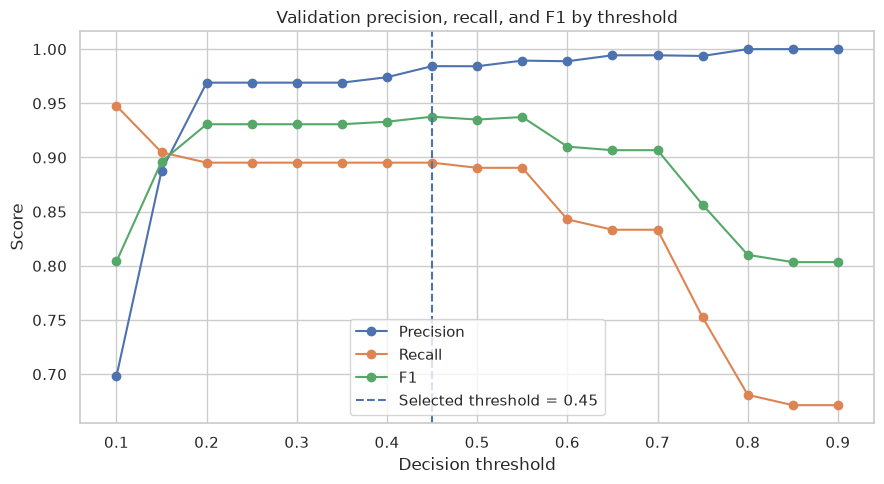

In [28]:
threshold_plot = threshold_results.sort_values("threshold")
plt.figure(figsize=(9, 5))
for metric in ["precision", "recall", "f1"]:
    plt.plot(
        threshold_plot["threshold"],
        threshold_plot[metric],
        marker="o",
        label=metric.capitalize(),
    )
plt.axvline(best_threshold, linestyle="--", label=f"Selected threshold = {best_threshold:.2f}")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Validation precision, recall, and F1 by threshold")
plt.legend()
plt.tight_layout()
plt.show()

## 14. Final evaluation on the held-out test set

This is the final, one-time evaluation of the selected model and threshold. Do not use these test results to go back and tune model parameters or select another threshold.

In [29]:
test_probabilities = selected_model.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= best_threshold).astype(int)

test_metrics = {
    "model": selected_model_name,
    "threshold": best_threshold,
    "roc_auc": roc_auc_score(y_test, test_probabilities),
    "accuracy": accuracy_score(y_test, test_predictions),
    "precision": precision_score(y_test, test_predictions, zero_division=0),
    "recall": recall_score(y_test, test_predictions, zero_division=0),
    "f1": f1_score(y_test, test_predictions, zero_division=0),
}

display(pd.DataFrame([test_metrics]).set_index("model").T.rename(columns={selected_model_name: "test"}))

model,test
threshold,0.450
roc_auc,0.990
accuracy,0.981
precision,0.966
recall,0.943
f1,0.954


Classification report — test set:
               precision    recall  f1-score   support

No stroke (0)       0.98      0.99      0.99       773
   Stroke (1)       0.97      0.94      0.95       209

     accuracy                           0.98       982
    macro avg       0.98      0.97      0.97       982
 weighted avg       0.98      0.98      0.98       982



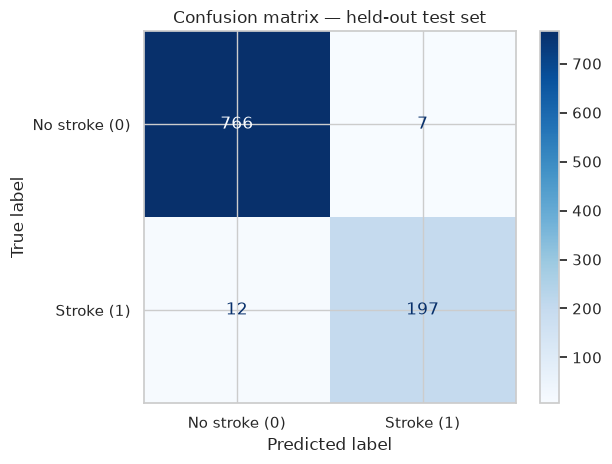

In [30]:
print("Classification report — test set:")
print(classification_report(
    y_test,
    test_predictions,
    target_names=["No stroke (0)", "Stroke (1)"],
    zero_division=0,
))

cm = confusion_matrix(y_test, test_predictions)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No stroke (0)", "Stroke (1)"],
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix — held-out test set")
plt.tight_layout()
plt.show()

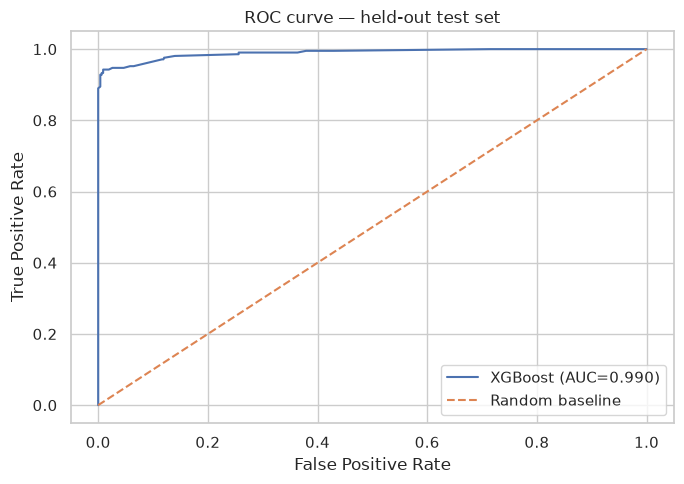

In [31]:
fpr, tpr, _ = roc_curve(y_test, test_probabilities)
test_auc = roc_auc_score(y_test, test_probabilities)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"{selected_model_name} (AUC={test_auc:.3f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC curve — held-out test set")
plt.legend()
plt.tight_layout()
plt.show()

## 15. Inspect model feature importance

For tree-based models, feature importance provides a simple view of which encoded features contributed most to the fitted model. Importance is not causal and should not be interpreted as a medical explanation.

,feature,importance
1,avg_glucose_level,0.474
9,hypertension,0.354
0,age,0.150
2,bmi,0.022
3,ever_married=no,0.000
4,ever_married=yes,0.000
5,gender=female,0.000
7,gender=other,0.000
6,gender=male,0.000
8,heart_disease,0.000


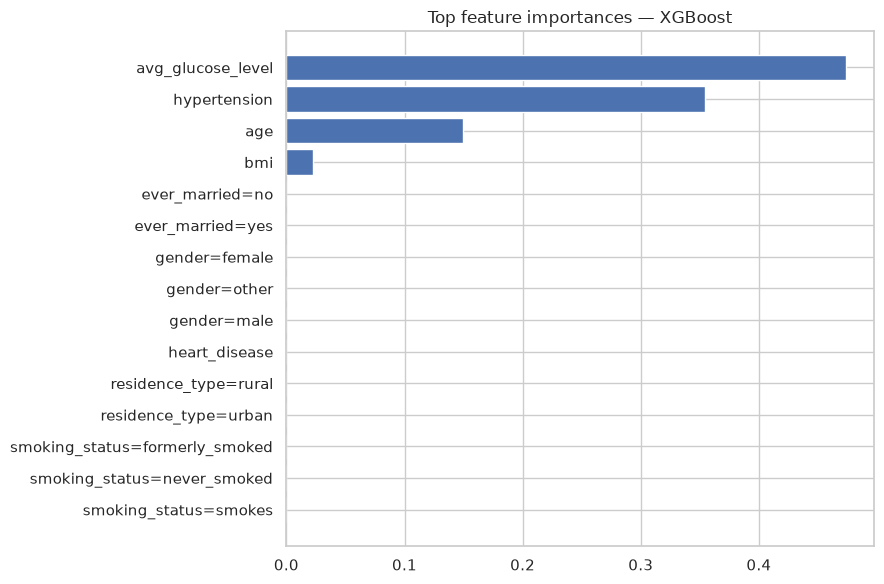

In [32]:
if hasattr(selected_model, "feature_importances_"):
    importance_values = selected_model.feature_importances_
    importance_df = pd.DataFrame({
        "feature": feature_names,
        "importance": importance_values,
    }).sort_values("importance", ascending=False).head(15)

    display(importance_df)

    plt.figure(figsize=(9, 6))
    plt.barh(importance_df["feature"], importance_df["importance"])
    plt.gca().invert_yaxis()
    plt.title(f"Top feature importances — {selected_model_name}")
    plt.tight_layout()
    plt.show()
elif hasattr(selected_model, "coef_"):
    coefficient_df = pd.DataFrame({
        "feature": feature_names,
        "coefficient": selected_model.coef_[0],
    })
    coefficient_df["absolute_coefficient"] = coefficient_df["coefficient"].abs()
    coefficient_df = coefficient_df.sort_values(
        "absolute_coefficient", ascending=False
    ).head(15)
    display(coefficient_df)
else:
    print("This estimator does not expose native feature importance.")

## 16. Save the model package

The package includes the selected estimator, fitted `DictVectorizer`, selected threshold, and training-derived imputation values. Keeping these objects together helps the API apply the same preprocessing and encoding rules as training.

**API integration note:** the current `predict.py` can continue to use `package["model"]`, `package["dv"]`, and `package["threshold"]`. For robust handling of missing incoming fields, the API should also apply `numerical_medians` and `categorical_modes` before calling `dv.transform()`.

In [33]:
model_package = {
    "model": selected_model,
    "dv": dv,
    "threshold": best_threshold,
    "model_name": selected_model_name,
    "numerical_medians": numerical_medians.to_dict(),
    "categorical_modes": categorical_modes.to_dict(),
    "numerical_features": NUMERICAL_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "feature_columns": FEATURES,
    "bmi_upper_cap": 60,
    "random_state": RANDOM_STATE,
    "test_metrics": test_metrics,
}

with open(MODEL_PATH, "wb") as f_out:
    pickle.dump(model_package, f_out)

print(f"Model package saved: {MODEL_PATH.resolve()}")
print(f"Package size: {MODEL_PATH.stat().st_size:,} bytes")

Model package saved: /workspaces/MLzoomcamp-26_homework/07-Midterm/stroke-prediction/stroke_prediction_model.bin
Package size: 100,276 bytes


## 17. Reload and verify the saved artifact

We reload the serialized package and compare its prediction probabilities against the in-memory estimator for the same test example.

In [34]:
with open(MODEL_PATH, "rb") as f_in:
    loaded_package = pickle.load(f_in)

loaded_model = loaded_package["model"]
loaded_dv = loaded_package["dv"]
loaded_threshold = loaded_package["threshold"]

sample_record = X_test_df.iloc[[0]].to_dict(orient="records")
sample_vector = loaded_dv.transform(sample_record)

loaded_probability = float(loaded_model.predict_proba(sample_vector)[0, 1])
original_probability = float(selected_model.predict_proba(X_test[:1])[0, 1])

print(f"Loaded model: {loaded_package['model_name']}")
print(f"Threshold: {loaded_threshold:.2f}")
print(f"Original probability: {original_probability:.8f}")
print(f"Reloaded probability: {loaded_probability:.8f}")
print(f"Same prediction probability: {np.isclose(original_probability, loaded_probability)}")

Loaded model: XGBoost
Threshold: 0.45
Original probability: 0.00681088
Reloaded probability: 0.00681088
Same prediction probability: True


## 18. Example prediction payload for the API

The following dictionary demonstrates the feature names and value formats expected by the existing Flask endpoint. Use lowercase category values, consistent with the preprocessing performed during training.

In [35]:
example_patient = {
    "gender": "female",
    "age": 67.0,
    "hypertension": 0,
    "heart_disease": 0,
    "ever_married": "yes",
    "work_type": "private",
    "residence_type": "urban",
    "avg_glucose_level": 120.5,
    "bmi": 28.4,
    "smoking_status": "never_smoked",
}

example_vector = loaded_dv.transform([example_patient])
example_probability = float(loaded_model.predict_proba(example_vector)[0, 1])
example_prediction = int(example_probability >= loaded_threshold)

print({
    "stroke_probability": round(example_probability, 4),
    "stroke_prediction": example_prediction,
    "threshold": loaded_threshold,
})

{'stroke_probability': 0.0969, 'stroke_prediction': 0, 'threshold': 0.45}


## 19. Conclusion

This notebook compares four classification approaches using a consistent training/validation/test workflow. Model selection and threshold tuning are performed on validation data, while the test partition is reserved for the final evaluation.

When reporting results, include:
- The selected model and its validation ROC AUC.
- The validation-based decision threshold and why it was selected.
- Test ROC AUC, precision, recall, F1, accuracy, and confusion matrix.
- The limitations of the dataset and the educational-only purpose of the model.

### Reproducibility checklist

- [ ] Dataset file is available at `DATA_PATH`.
- [ ] Run all cells from top to bottom in a fresh kernel.
- [ ] Confirm there are no execution errors.
- [ ] Confirm the saved model package is generated.
- [ ] Verify that `predict.py` applies the stored imputation values when needed.
- [ ] Rebuild and test the Docker image after any model or API changes.

**Medical and ethical limitation:** the model learns patterns from a specific dataset and may be biased, incomplete, or poorly calibrated for other populations. It must not be used for screening, diagnosis, treatment, or emergency decisions.